# The Income Divide in Financial Inclusion

## 1. Data Preparation and Cleaning

This project examines income-related differences in financial access and behaviour across developing and emerging economies.

We use the World Bank Global Findex Database 2025, focusing on the 2021 survey.

Our analysis compares the poorest 40% and richest 60% of adults within each economy.

We start by loading the original dataset, selecting our target economies and financial indicators, and checking the data before carrying out the multivariate analysis.

### 1.1 Importing Libraries

The following libraries are used for data preparation, visualisation, PCA, Factor Analysis and Cluster Analysis.

In [1]:


import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from factor_analyzer import FactorAnalyzer
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.rotator import Rotator

import pingouin as pg
from numpy.linalg import inv

from sklearn.cluster import KMeans
from sklearn.metrics import explained_variance_score
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

### 1.2 Loading the Dataset



In [2]:

df = pd.read_excel(
    "data/GlobalFindexDatabase2025.xlsx",
    sheet_name="Data"
)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (8578, 466)


,countrynewwb,codewb,year,pop_adult,regionwb24_hi,incomegroupwb24,group,group2,account.t.d,fiaccount.t.d,...,con32d,con32d.s,con32e,con32e.s,con32f,con32f.s,con32g,con32g.s,con32h,con32h.s
0,Economy,Economy code,Year,Adult population,Region,Income group,Demographic group,Demographic sub-group,"Account (%, age 15+)",Bank or similar financial institution account ...,...,Main reason for not owning a smartphone: diffi...,Main reason for not owning a smartphone: diffi...,Main reason for not owning a smartphone: famil...,Main reason for not owning a smartphone: famil...,Main reason for not owning a smartphone: safet...,Main reason for not owning a smartphone: safet...,Main reason for not owning a smartphone: uses ...,Main reason for not owning a smartphone: uses ...,Main reason for not owning a smartphone: no ne...,Main reason for not owning a smartphone: no ne...
1,Afghanistan,AFG,2011,14575546,South Asia (excluding high income),Low income,all,all,0.09005,0.09005,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Albania,ALB,2011,2281010,Europe & Central Asia (excluding high income),Upper middle income,all,all,0.282681,0.282681,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Algeria,DZA,2011,26251587,Middle East & North Africa (excluding high inc...,Lower middle income,all,all,0.332861,0.332861,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,2011,12779501,Sub-Saharan Africa (excluding high income),Lower middle income,all,all,0.392035,0.392035,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.3 Selecting the 2021 Survey



In [3]:

data_2021 = df[df["year"].astype(str) == "2021"].copy()

print("2021 dataset shape:", data_2021.shape)

2021 dataset shape: (1483, 466)


### 1.4 Checking World Bank Country Income Classifications



In [4]:

print(data_2021["incomegroupwb24"].value_counts(dropna=False))

incomegroupwb24
High income            484
Lower middle income    396
Upper middle income    339
Low income             132
NaN                    132
Name: count, dtype: int64


### 1.5 Selecting Developing and Emerging Economies

The analysis focuses on low-income, lower-middle-income and upper-middle-income economies, based on the World Bank income classification.

High-income economies and other aggregates are excluded because they are outside the scope of this analysis.

In [5]:

target_income_groups = [
    "Low income",
    "Lower middle income",
    "Upper middle income"
]

developing_2021 = data_2021[
    data_2021["incomegroupwb24"].isin(target_income_groups)
].copy()

print("Dataset shape:", developing_2021.shape)
print("Number of economies:", developing_2021["countrynewwb"].nunique())

Dataset shape: (867, 466)
Number of economies: 79


### 1.6 Selecting the Income Groups

The analysis compares the poorest 40% and richest 60% of adults within each economy.

Only observations belonging to these two income groups are retained for the analysis.

In [6]:

income_data = developing_2021[
    developing_2021["group"] == "income"
].copy()

print("Dataset shape:", income_data.shape)

print("\nIncome group counts:")
print(income_data["group2"].value_counts())

print("\nNumber of economies:",
      income_data["countrynewwb"].nunique())

Dataset shape: (158, 466)

Income group counts:
group2
richest 60%    79
poorest 40%    79
Name: count, dtype: int64

Number of economies: 79


### 1.7 Selecting the Financial Indicators

Nine financial indicators are selected to examine financial access, payment behaviour, saving, borrowing and financial resilience.



In [7]:

financial_indicators = [
    "fiaccount.t.d",
    "g20.made",
    "g20.received",
    "fin30",
    "fing2p",
    "save.any.t.d",
    "borrow.any.t.d",
    "fin24aP",
    "fin24fam"
]

# country information and the selected indicators
financial_data = income_data[
    ["countrynewwb", "incomegroupwb24", "group2"] + financial_indicators
].copy()

print("Dataset shape:", financial_data.shape)
display(financial_data.head())

Dataset shape: (158, 12)


,countrynewwb,incomegroupwb24,group2,fiaccount.t.d,g20.made,g20.received,fin30,fing2p,save.any.t.d,borrow.any.t.d,fin24aP,fin24fam
2909,Afghanistan,Low income,richest 60%,NaN,NaN,NaN,0.213004,NaN,NaN,0.626834,0.909939,0.662659
2910,Afghanistan,Low income,poorest 40%,NaN,NaN,NaN,0.173275,NaN,NaN,0.759081,0.836295,0.709814
2911,Albania,Upper middle income,richest 60%,0.554087,0.203209,0.354313,0.728757,0.346227,0.397624,0.376443,0.946533,0.508638
2912,Albania,Upper middle income,poorest 40%,0.272656,0.045598,0.157187,0.728906,0.30913,0.19779,0.502741,0.843719,0.586151
2913,Algeria,Lower middle income,richest 60%,0.521719,0.164538,0.353011,0.443505,0.344911,0.528317,0.327986,0.926603,0.503196


### 1.8 Renaming the Variables

The original World Bank variable names are renamed to make them easier to understand and interpret.



In [8]:
# Rename the columns
financial_data = financial_data.rename(columns={
    "countrynewwb": "country",
    "incomegroupwb24": "country_income_group",
    "group2": "income_group",
    "fiaccount.t.d": "financial_institution_account",
    "g20.made": "paid_digitally",
    "g20.received": "received_digitally",
    "fin30": "made_utility_payment",
    "fing2p": "received_govt_payment",
    "save.any.t.d": "saved_money",
    "borrow.any.t.d": "borrowed_from_any_source",
    "fin24aP": "could_raise_emergency_funds",
    "fin24fam": "family_main_emergency_source"
})

print("Dataset shape:", financial_data.shape)
print("\nColumn names:")
print(financial_data.columns.tolist())

Dataset shape: (158, 12)

Column names:
['country', 'country_income_group', 'income_group', 'financial_institution_account', 'paid_digitally', 'received_digitally', 'made_utility_payment', 'received_govt_payment', 'saved_money', 'borrowed_from_any_source', 'could_raise_emergency_funds', 'family_main_emergency_source']


### 1.9 Checking Data Types

The data types are checked to ensure that the financial indicators are stored as numerical values before carrying out the analysis.

In [9]:

print(financial_data.dtypes)

country                             str
country_income_group                str
income_group                        str
financial_institution_account    object
paid_digitally                   object
received_digitally               object
made_utility_payment             object
received_govt_payment            object
saved_money                      object
borrowed_from_any_source         object
could_raise_emergency_funds      object
family_main_emergency_source     object
dtype: object


### 1.10 Converting Financial Indicators to Numeric Values

The nine financial indicators were stored as object data types. They are converted to numerical values so they can be used in the statistical analysis.

Values that cannot be converted are treated as missing values and will be examined in the next step.

In [10]:
# Select the nine financial indicator columns
indicator_columns = financial_data.columns[3:]

# Convert the indicators to numerical values
financial_data[indicator_columns] = financial_data[indicator_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Check the data types again
print(financial_data.dtypes)

country                              str
country_income_group                 str
income_group                         str
financial_institution_account    float64
paid_digitally                   float64
received_digitally               float64
made_utility_payment             float64
received_govt_payment            float64
saved_money                      float64
borrowed_from_any_source         float64
could_raise_emergency_funds      float64
family_main_emergency_source     float64
dtype: object


### 1.11 Checking Missing Values

The nine financial indicators are checked for missing values.

This helps identify which indicators have incomplete data before deciding how to handle the missing values.

In [11]:
# Count missing values for each financial indicator
missing_values = financial_data[indicator_columns].isna().sum()

print("Missing values for each indicator:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values for each indicator:
financial_institution_account     4
paid_digitally                   10
received_digitally               10
made_utility_payment              2
received_govt_payment            26
saved_money                       2
borrowed_from_any_source          0
could_raise_emergency_funds       0
family_main_emergency_source      0
dtype: int64

Total missing values: 54


### 1.12 Checking Missing Values by Economy

Missing values were found in some financial indicators, with government payments having the highest number.

The affected economies and income groups are checked before deciding how to handle the missing data.

In [12]:
# observations with at least one missing indicator
rows_with_missing = financial_data[
    financial_data[indicator_columns].isna().any(axis=1)
]

print("Observations with missing values:", len(rows_with_missing))
print("Economies affected:", rows_with_missing["country"].nunique())

# affected economies and income groups
print(rows_with_missing[["country", "income_group"]].to_string(index=False))

Observations with missing values: 30
Economies affected: 15
         country income_group
     Afghanistan  richest 60%
     Afghanistan  poorest 40%
           Benin  richest 60%
           Benin  poorest 40%
    Burkina Faso  richest 60%
    Burkina Faso  poorest 40%
        Cameroon  richest 60%
        Cameroon  poorest 40%
     Congo, Rep.  richest 60%
     Congo, Rep.  poorest 40%
   Cote d'Ivoire  richest 60%
   Cote d'Ivoire  poorest 40%
Egypt, Arab Rep.  richest 60%
Egypt, Arab Rep.  poorest 40%
          Guinea  richest 60%
          Guinea  poorest 40%
            Iraq  richest 60%
            Iraq  poorest 40%
         Lao PDR  richest 60%
         Lao PDR  poorest 40%
         Lebanon  richest 60%
         Lebanon  poorest 40%
         Nigeria  richest 60%
         Nigeria  poorest 40%
        Pakistan  richest 60%
        Pakistan  poorest 40%
     South Sudan  richest 60%
     South Sudan  poorest 40%
        Tanzania  richest 60%
        Tanzania  poorest 40%


### 1.13 Checking the Missing Data Pattern

Missing values were found in 15 economies, affecting 30 observations.

The missing data pattern is check to identify which indicators are incomplete in each economy before deciding how to handle them.

In [13]:
# find the missing indicators for each affected observation
missing_pattern = rows_with_missing[
    ["country", "income_group"] + list(indicator_columns)
].copy()


missing_pattern[indicator_columns] = (
    missing_pattern[indicator_columns]
    .isna()
    .replace({True: "Missing", False: "Available"})
)

# print(missing_pattern.to_string(index=False))
display(missing_pattern)

,country,income_group,financial_institution_account,paid_digitally,received_digitally,made_utility_payment,received_govt_payment,saved_money,borrowed_from_any_source,could_raise_emergency_funds,family_main_emergency_source
2909,Afghanistan,richest 60%,Missing,Missing,Missing,Available,Missing,Missing,Available,Available,Available
2910,Afghanistan,poorest 40%,Missing,Missing,Missing,Available,Missing,Missing,Available,Available,Available
2929,Benin,richest 60%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2930,Benin,poorest 40%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2941,Burkina Faso,richest 60%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2942,Burkina Faso,poorest 40%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2945,Cameroon,richest 60%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2946,Cameroon,poorest 40%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2961,"Congo, Rep.",richest 60%,Available,Available,Available,Available,Missing,Available,Available,Available,Available
2962,"Congo, Rep.",poorest 40%,Available,Available,Available,Available,Missing,Available,Available,Available,Available


### 1.14 Comparing the Effect of Missing Values

Government payments had the highest number of missing values.

We compared the number of economies we could keep with all nine indicators and without government payments.

This will help decide whether removing the indicator is better than losing more economies from the analysis.

In [14]:
# Option 1: Keep all nine indicators
complete_nine = financial_data.dropna(subset=indicator_columns)

# Option 2: Exclude government payments
eight_indicators = [
    col for col in indicator_columns
    if col != "received_govt_payment"
]

complete_eight = financial_data.dropna(subset=eight_indicators)

print("With 9 indicators:")
print("Economies:", complete_nine["country"].nunique())
print("Observations:", len(complete_nine))

print("\nWith 8 indicators:")
print("Economies:", complete_eight["country"].nunique())
print("Observations:", len(complete_eight))

With 9 indicators:
Economies: 64
Observations: 128

With 8 indicators:
Economies: 73
Observations: 146


### 1.15 Creating the Cleaned Dataset

We created a cleaned dataset using the eight selected financial indicators.

The dataset includes only economies with complete data for these indicators. We also kept the country name, country income group and the two income groups for comparison.

In [15]:
# cleaned dataset with eight indicators
cleaned_data = complete_eight[
    ["country", "country_income_group", "income_group"] + eight_indicators
].copy()

# size of the cleaned dataset
print("Dataset shape:", cleaned_data.shape)
print("Number of economies:", cleaned_data["country"].nunique())


display(cleaned_data.head())

Dataset shape: (146, 11)
Number of economies: 73


,country,country_income_group,income_group,financial_institution_account,paid_digitally,received_digitally,made_utility_payment,saved_money,borrowed_from_any_source,could_raise_emergency_funds,family_main_emergency_source
2911,Albania,Upper middle income,richest 60%,0.554087,0.203209,0.354313,0.728757,0.397624,0.376443,0.946533,0.508638
2912,Albania,Upper middle income,poorest 40%,0.272656,0.045598,0.157187,0.728906,0.197790,0.502741,0.843719,0.586151
2913,Algeria,Lower middle income,richest 60%,0.521719,0.164538,0.353011,0.443505,0.528317,0.327986,0.926603,0.503196
2914,Algeria,Lower middle income,poorest 40%,0.319059,0.042143,0.209780,0.306764,0.349021,0.448286,0.794992,0.471308
2915,Argentina,Upper middle income,richest 60%,0.714391,0.642490,0.405070,0.647093,0.477713,0.512324,0.897510,0.371326


### 1.16 Checking Income Groups and Duplicates

The dataset was checked to confirm that each economy has both income groups and that there are no duplicate observations.

This is important for comparing the poorest 40% and richest 60% within each economy.

In [16]:
# Count the number of income groups for each economy
income_group_counts = cleaned_data.groupby("country")["income_group"].nunique()

# Check for duplicate country and income group combinations
duplicates = cleaned_data.duplicated(
    subset=["country", "income_group"]
).sum()

print("Economies with both income groups:", (income_group_counts == 2).sum())
print("Economies missing an income group:", (income_group_counts != 2).sum())
print("Duplicate observations:", duplicates)

print("\nIncome group distribution:")
display(cleaned_data["income_group"].value_counts().to_frame("Observations"))

Economies with both income groups: 73
Economies missing an income group: 0
Duplicate observations: 0

Income group distribution:


,Observations
income_group,
richest 60%,73
poorest 40%,73


### 1.17 Checking the Range of Financial Indicators

The eight financial indicators are measured as proportions, with values expected to range from 0 to 1.

The minimum and maximum values are checked to identify any values outside this range.

In [17]:
# Check minimum and maximum values of each indicator
range_check = cleaned_data[eight_indicators].agg(["min", "max"]).T


range_check.columns = ["Minimum", "Maximum"]

# Check for values outside the expected range
range_check["Outside 0–1 Range"] = (
    (range_check["Minimum"] < 0) |
    (range_check["Maximum"] > 1)
).map({True: "Yes", False: "No"})

display(range_check)

,Minimum,Maximum,Outside 0–1 Range
financial_institution_account,0.097278,0.985657,No
paid_digitally,0.042143,0.927445,No
received_digitally,0.065082,0.938164,No
made_utility_payment,0.099237,0.853334,No
saved_money,0.083964,0.786939,No
borrowed_from_any_source,0.217651,0.792318,No
could_raise_emergency_funds,0.312577,0.989466,No
family_main_emergency_source,0.116725,0.664672,No


### 1.18 Exporting the Cleaned Dataset

The cleaned dataset was saved as a CSV file for further analysis.

It contains 73 economies, with two income groups per economy and eight financial indicators. The original dataset remains unchanged.

In [18]:
from pathlib import Path

# output folder
output_folder = Path("data/processed")
output_folder.mkdir(parents=True, exist_ok=True)

# Save
output_file = output_folder / "financial_inclusion_cleaned_2021.csv"

cleaned_data.to_csv(output_file, index=False)

# Confirmation
print("File saved successfully:", output_file.exists())
print("File location:", output_file)
print("Observations:", len(cleaned_data))
print("Economies:", cleaned_data["country"].nunique())

File saved successfully: True
File location: data\processed\financial_inclusion_cleaned_2021.csv
Observations: 146
Economies: 73


## 2. Exploratory Data Analysis

### 2.1 Overall Summary Statistics

Descriptive statistics were calculated to understand the eight financial indicators across the 146 observations.



In [26]:
# Summary statistics for the eight financial indicators
summary_stats = cleaned_data[eight_indicators].describe()
variance = cleaned_data[eight_indicators].var()
quantiles = cleaned_data[eight_indicators].quantile(
    [0.10, 0.25, 0.50, 0.75, 0.90]
)

print("Summary Statistics:")
display(summary_stats.round(3))

print("Variance:")
display(variance.round(3).to_frame("Variance"))

print("Quantiles:")
display(quantiles.round(3))

Summary Statistics:


,financial_institution_account,paid_digitally,received_digitally,made_utility_payment,saved_money,borrowed_from_any_source,could_raise_emergency_funds,family_main_emergency_source
count,146.000,146.000,146.000,146.000,146.000,146.000,146.000,146.000
mean,0.507,0.430,0.350,0.470,0.431,0.482,0.852,0.376
std,0.258,0.219,0.195,0.200,0.157,0.105,0.101,0.102
min,0.097,0.042,0.065,0.099,0.084,0.218,0.313,0.117
25%,0.288,0.245,0.204,0.325,0.307,0.411,0.807,0.313
50%,0.460,0.402,0.302,0.491,0.431,0.490,0.866,0.373
75%,0.759,0.584,0.460,0.629,0.528,0.544,0.927,0.435
max,0.986,0.927,0.938,0.853,0.787,0.792,0.989,0.665


Variance:


,Variance
financial_institution_account,0.066
paid_digitally,0.048
received_digitally,0.038
made_utility_payment,0.040
saved_money,0.025
borrowed_from_any_source,0.011
could_raise_emergency_funds,0.010
family_main_emergency_source,0.010


Quantiles:


,financial_institution_account,paid_digitally,received_digitally,made_utility_payment,saved_money,borrowed_from_any_source,could_raise_emergency_funds,family_main_emergency_source
0.10,0.185,0.161,0.148,0.195,0.213,0.338,0.720,0.247
0.25,0.288,0.245,0.204,0.325,0.307,0.411,0.807,0.313
0.50,0.460,0.402,0.302,0.491,0.431,0.490,0.866,0.373
0.75,0.759,0.584,0.460,0.629,0.528,0.544,0.927,0.435
0.90,0.887,0.744,0.627,0.729,0.645,0.596,0.959,0.502


### 2.2 Checking for Outliers

Box plots are used to check for possible outliers in the eight financial indicators.

This helps identify unusually high or low values before carrying out the multivariate analysis.

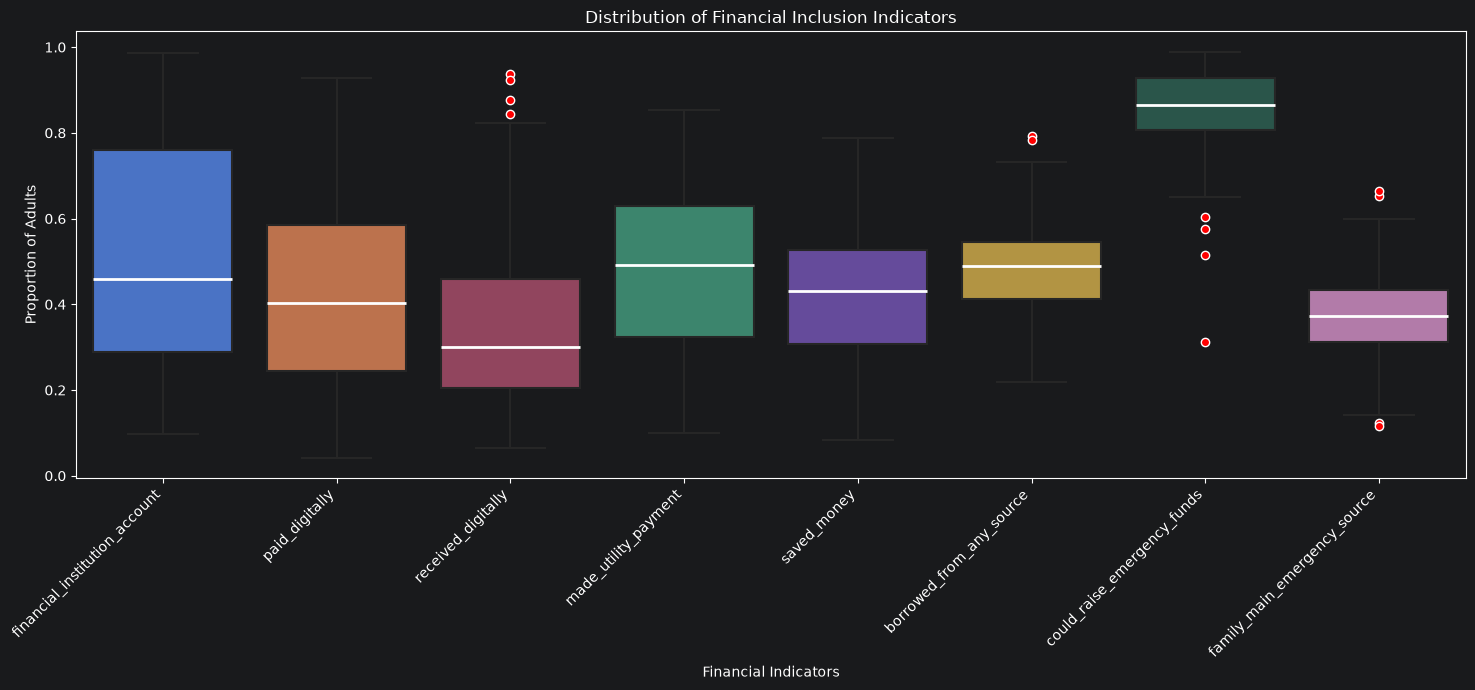

In [20]:

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=cleaned_data[eight_indicators],
    linewidth=1.5,
    medianprops={"color": "white", "linewidth": 2},
    flierprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "white",
        "markersize": 6,
        "alpha": 1
    }
)

plt.title("Distribution of Financial Inclusion Indicators")
plt.ylabel("Proportion of Adults")
plt.xlabel("Financial Indicators")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

### 2.3 Identifying Possible Outliers

The Interquartile Range (IQR) method was used to identify possible outliers in the eight financial indicators.

The affected economies and income groups were identified to understand where these unusual values occur.

In [21]:
# Calculate the IQR limits for each indicator
Q1 = cleaned_data[eight_indicators].quantile(0.25)
Q3 = cleaned_data[eight_indicators].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify values outside the IQR limits
outlier_mask = (
    cleaned_data[eight_indicators].lt(lower_limit) |
    cleaned_data[eight_indicators].gt(upper_limit)
)

# Count possible outliers for each indicator
outlier_summary = outlier_mask.sum().to_frame("Possible Outliers")

display(outlier_summary)

,Possible Outliers
financial_institution_account,0
paid_digitally,0
received_digitally,4
made_utility_payment,0
saved_money,0
borrowed_from_any_source,2
could_raise_emergency_funds,4
family_main_emergency_source,4


### 2.4 Identifying Economies with Possible Outliers

The economies and income groups with possible outliers were identified using the IQR limits.

The actual values were also examined to understand which observations are unusually high or low.

In [22]:
# observations flagged as possible outliers
outlier_details = cleaned_data.loc[
    outlier_mask.any(axis=1),
    ["country", "income_group"] + eight_indicators
].copy()

# Keep only values flagged as outliers
outlier_details[eight_indicators] = outlier_details[
    eight_indicators
].where(outlier_mask)

# Display one row for each outlier value
outlier_details = outlier_details.melt(
    id_vars=["country", "income_group"],
    var_name="Financial Indicator",
    value_name="Value"
).dropna(subset=["Value"])

# Convert proportions to percentages
outlier_details["Value (%)"] = (
    outlier_details["Value"] * 100
).round(2)

outlier_details = outlier_details[
    ["country", "income_group", "Financial Indicator", "Value (%)"]
].sort_values(["Financial Indicator", "country"])

display(outlier_details.reset_index(drop=True))

,country,income_group,Financial Indicator,Value (%)
0,Kenya,richest 60%,borrowed_from_any_source,79.23
1,Uganda,richest 60%,borrowed_from_any_source,78.41
2,Mozambique,poorest 40%,could_raise_emergency_funds,51.49
3,Paraguay,poorest 40%,could_raise_emergency_funds,57.46
4,Zambia,richest 60%,could_raise_emergency_funds,60.31
5,Zambia,poorest 40%,could_raise_emergency_funds,31.26
6,China,richest 60%,family_main_emergency_source,12.36
7,Kosovo,poorest 40%,family_main_emergency_source,65.30
8,West Bank and Gaza,richest 60%,family_main_emergency_source,66.47
9,Zambia,poorest 40%,family_main_emergency_source,11.67


## 3. Income Differences (Research Question 1)

### 3.1 Financial Indicators by Income Group

The average values of the eight financial indicators were calculated separately for the poorest 40% and richest 60%.

This helps show how financial access and behaviour differ between the two income groups.

In [27]:
# mean of each indicator by income group
income_summary = cleaned_data.groupby("income_group")[eight_indicators].mean()


income_summary = income_summary * 100


display(income_summary.T.round(2))

income_group,poorest 40%,richest 60%
financial_institution_account,44.40,57.07
paid_digitally,34.30,51.62
received_digitally,28.92,41.08
made_utility_payment,42.99,51.05
saved_money,34.46,51.75
borrowed_from_any_source,46.41,49.96
could_raise_emergency_funds,80.49,89.95
family_main_emergency_source,38.69,36.60



The results show differences in financial access and behaviour between the poorest 40% and richest 60% across the 73 economies.

The richest 60% had higher average values for seven of the eight indicators. The largest differences were in making digital payments and saving money, with gaps of about 17 percentage points each.

Financial institution account ownership had a gap of about 13 percentage points, while borrowing from any source had a smaller gap of about 4 percentage points.

Family as the main emergency source was slightly higher among the poorest 40% (38.69%) than the richest 60% (36.60%).

These results show that income differences vary across financial services.

### 3.2 Income Gaps in Financial Inclusion

The income gap was calculated by subtracting the average value of the poorest 40% from the richest 60% for each financial indicator.

This helps identify which financial services have the largest and smallest differences between the two income groups.

In [30]:
# income gap in percentage points
income_gaps = income_summary.T.copy()

income_gaps["Income Gap (pp)"] = (
    income_gaps["richest 60%"] - income_gaps["poorest 40%"]
)


income_gaps = income_gaps.sort_values(
    "Income Gap (pp)", ascending=False
)

income_gaps.index.name = "Financial Indicator"
income_gaps.columns.name = None

display(income_gaps.round(2))

,poorest 40%,richest 60%,Income Gap (pp)
Financial Indicator,,,
paid_digitally,34.30,51.62,17.32
saved_money,34.46,51.75,17.29
financial_institution_account,44.40,57.07,12.68
received_digitally,28.92,41.08,12.16
could_raise_emergency_funds,80.49,89.95,9.46
made_utility_payment,42.99,51.05,8.05
borrowed_from_any_source,46.41,49.96,3.55
family_main_emergency_source,38.69,36.60,-2.10




The largest income gaps were found in making digital payments (17.32 percentage points) and saving money (17.29 percentage points).

Financial institution account ownership and receiving digital payments also showed noticeable gaps of 12.68 and 12.16 percentage points.

Borrowing from any source had the smallest positive gap (3.55 percentage points).

Family as the main emergency source was the only indicator with a negative gap (-2.10 percentage points), meaning its average value was slightly higher among the poorest 40%.

These results show that the size of the income gap differs across financial indicators.

### 3.3 Visualising Income Gaps

A horizontal bar chart was used to compare the income gaps across the eight financial indicators.

This makes it easier to identify which indicators have the largest and smallest differences between the two income groups.

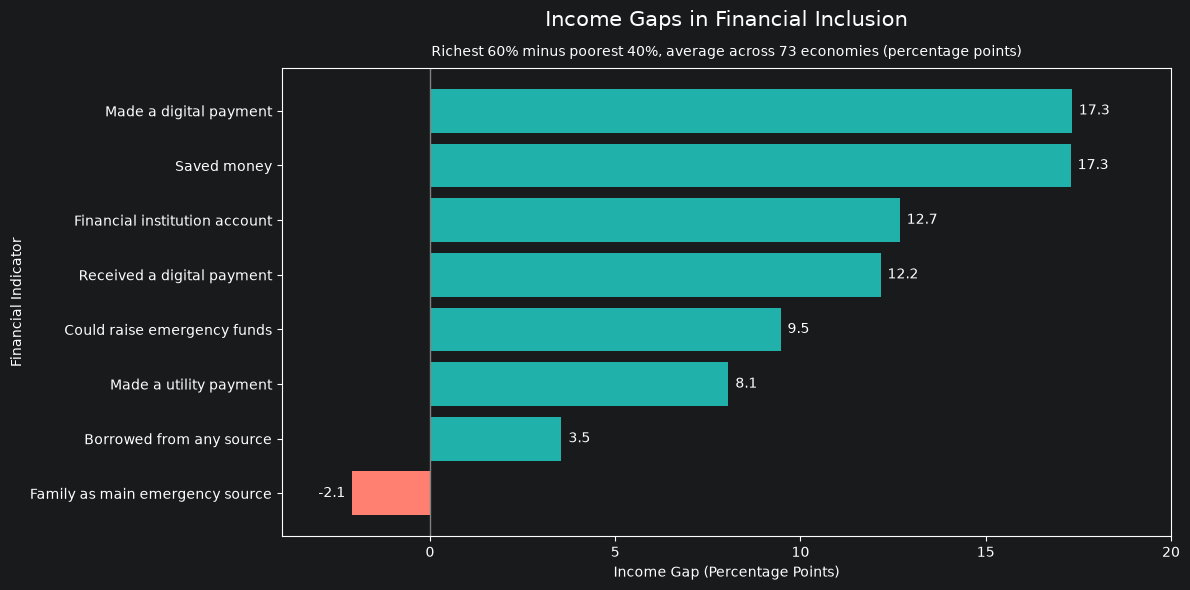

In [32]:

indicator_labels = {
    "paid_digitally": "Made a digital payment",
    "saved_money": "Saved money",
    "financial_institution_account": "Financial institution account",
    "received_digitally": "Received a digital payment",
    "could_raise_emergency_funds": "Could raise emergency funds",
    "made_utility_payment": "Made a utility payment",
    "borrowed_from_any_source": "Borrowed from any source",
    "family_main_emergency_source": "Family as main emergency source"
}


chart_data = income_gaps.copy()
chart_data.index = chart_data.index.map(indicator_labels)


colors = [
    "#20B2AA" if gap >= 0 else "#FF7F70"
    for gap in chart_data["Income Gap (pp)"]
]


fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    chart_data.index,
    chart_data["Income Gap (pp)"],
    color=colors
)


ax.bar_label(bars, fmt="%.1f", padding=5)


ax.set_title("Income Gaps in Financial Inclusion", fontsize=15, pad=30)

ax.text(
    0.5, 1.025,
    "Richest 60% minus poorest 40%, average across 73 economies (percentage points)",
    transform=ax.transAxes,
    ha="center",
    fontsize=10
)

ax.set_xlabel("Income Gap (Percentage Points)")
ax.set_ylabel("Financial Indicator")


ax.axvline(0, color="gray", linewidth=1)


ax.invert_yaxis()


ax.set_xlim(-4, 20)

plt.tight_layout()
plt.show()



The chart shows that making digital payments and saving money had the largest income gaps, at about 17 percentage points each.

Financial institution account ownership and receiving digital payments also showed noticeable differences between the two income groups.

Borrowing from any source had the smallest positive gap, while family as the main emergency source was the only indicator with a negative gap.

Overall, the differences were larger for some financial services than others.

## 4. Suitability Check for Multivariate Analysis

### 4.1 Standardising the Data

The eight financial indicators were standardised using StandardScaler.

This gives the indicators a mean of 0 and a standard deviation of 1, so they can be analysed on the same scale.

In [35]:

scaler = StandardScaler()

standardized_data = scaler.fit_transform(
    cleaned_data[eight_indicators]
)


standardized_data = pd.DataFrame(
    standardized_data,
    index=cleaned_data.index,
    columns=eight_indicators
)

display(standardized_data.head())

,financial_institution_account,paid_digitally,received_digitally,made_utility_payment,saved_money,borrowed_from_any_source,could_raise_emergency_funds,family_main_emergency_source
2911,0.181930,-1.035702,0.022426,1.300380,-0.213692,-1.007864,0.933693,1.303351
2912,-0.913442,-1.756776,-0.993272,1.301130,-1.492586,0.199676,-0.084051,2.067582
2913,0.055948,-1.212624,0.015715,-0.134197,0.622715,-1.471157,0.736402,1.249694
2914,-0.732835,-1.772585,-0.722284,-0.821888,-0.524738,-0.320968,-0.566392,0.935299
2915,0.805854,0.974019,0.283949,0.889683,0.298860,0.291300,0.448420,-0.050468


In [37]:
# Check the mean and standard deviation after standardisation
standardisation_check = pd.DataFrame({
    "Mean": standardized_data.mean(),
    "Standard Deviation": standardized_data.std(ddof=0)
})

display(standardisation_check.round(3))

,Mean,Standard Deviation
financial_institution_account,-0.0,1.0
paid_digitally,0.0,1.0
received_digitally,-0.0,1.0
made_utility_payment,-0.0,1.0
saved_money,0.0,1.0
borrowed_from_any_source,-0.0,1.0
could_raise_emergency_funds,-0.0,1.0
family_main_emergency_source,-0.0,1.0


All eight financial indicators were successfully standardised.

The mean values were approximately 0, while the standard deviations were 1.

This confirms that the indicators are now on the same scale for PCA and Factor Analysis.



### 4.2 Correlation Analysis

The correlation matrix was used to examine the relationships between the eight financial indicators.

This helps show which indicators are strongly or weakly related before applying PCA and Factor Analysis.

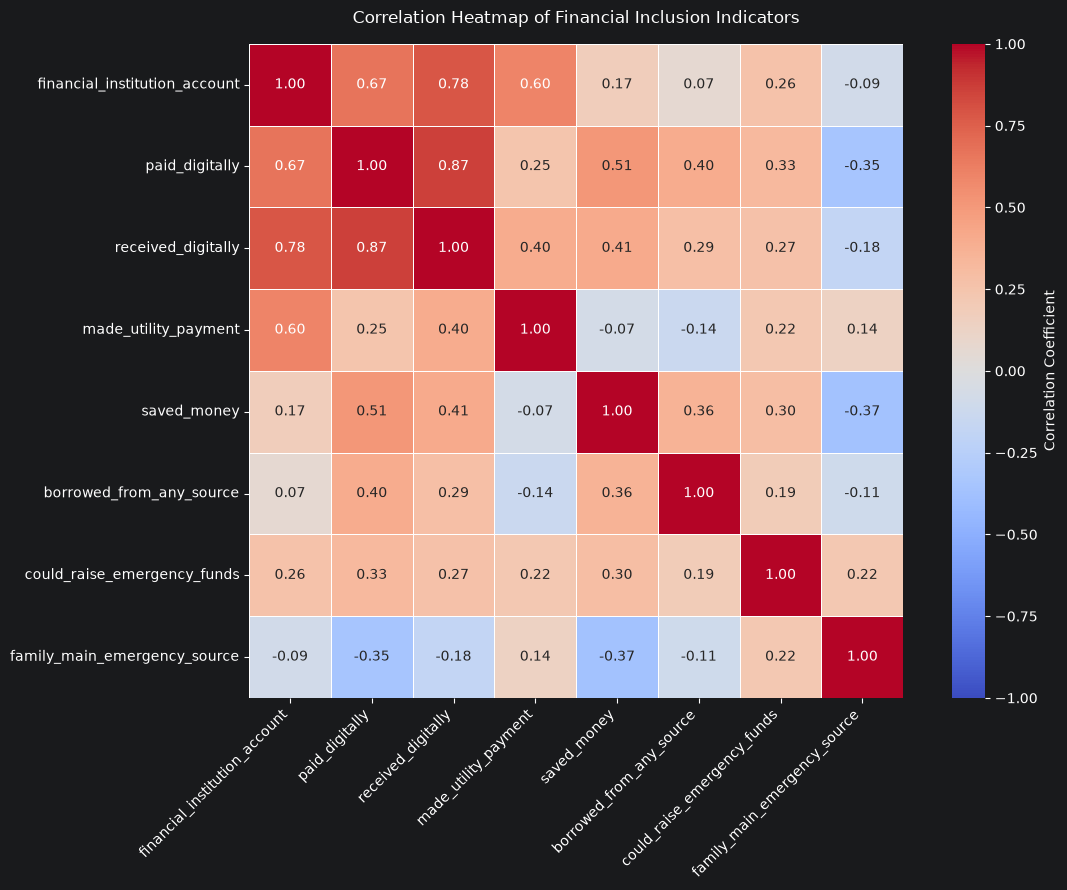

In [41]:
correlation_matrix = standardized_data.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 10},
    cbar_kws={"label": "Correlation Coefficient"}
)

plt.title("Correlation Heatmap of Financial Inclusion Indicators", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### 4.3 Partial Correlation Analysis

Partial correlation was used to check the relationship between two financial indicators while taking the other indicators into account.

This helps show whether the relationship between two indicators is still strong after considering the other variables.

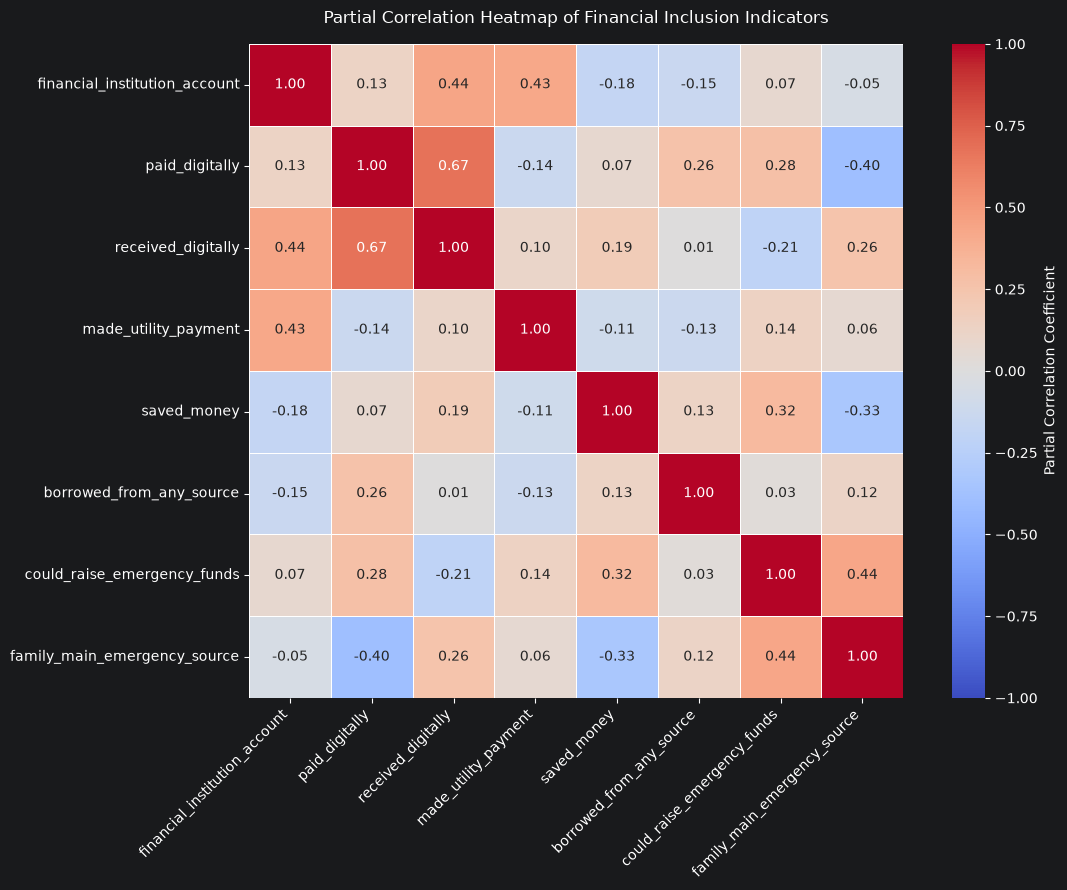

In [42]:

partial_corr_matrix = standardized_data.pcorr()


plt.figure(figsize=(12, 9))

sns.heatmap(
    partial_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 10},
    cbar_kws={"label": "Partial Correlation Coefficient"}
)

plt.title("Partial Correlation Heatmap of Financial Inclusion Indicators", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Most partial correlations were small, with 21 out of 28 values between -0.30 and 0.30.

Making and receiving digital payments had the highest partial correlation (0.67), showing that they remain strongly related after considering the other indicators.

Raising emergency funds and family as the main emergency source also had a positive partial correlation (0.44). According to the World Bank definition, the family emergency source indicator includes adults who could raise emergency funds and identified family or friends as their main source. This means the two indicators partly overlap.

Overall, most relationships became weaker after taking the other indicators into account. This supports further investigation using Factor Analysis.

### 4.4 Kaiser–Meyer–Olkin (KMO) Test

The KMO test was used to check whether the eight financial indicators are suitable for Factor Analysis.

Both the overall KMO and the individual KMO values were examined to see how well the indicators are related.

In [43]:
# Calculate the overall and individual KMO values
kmo_per_indicator, kmo_overall = calculate_kmo(
    standardized_data
)


print("Overall KMO:", round(kmo_overall, 3))


kmo_table = pd.DataFrame({
    "Financial Indicator": eight_indicators,
    "KMO Value": kmo_per_indicator.round(3)
})

display(kmo_table)

Overall KMO: 0.684


,Financial Indicator,KMO Value
0,financial_institution_account,0.772
1,paid_digitally,0.705
2,received_digitally,0.702
3,made_utility_payment,0.720
4,saved_money,0.727
5,borrowed_from_any_source,0.760
6,could_raise_emergency_funds,0.520
7,family_main_emergency_source,0.414


The overall KMO value was 0.684, which is generally acceptable for Factor Analysis.

Six of the eight indicators had individual KMO values above 0.70. However, the ability to raise emergency funds had a lower KMO value of 0.520, while family as the main emergency source had the lowest value of 0.414.

These results show that most indicators have acceptable KMO values, but the two emergency-related indicators may not fit well with the others.

All eight indicators were kept for further analysis. The factor loadings and communalities will also be examined before deciding whether any indicator should be removed.